# Penguins EDA

### Introduction
What the data is: Measurements of 344 penguins from three species living on three islands in the Palmer Archipelago (Antarctica). The data was collected by Dr. Kristen Gorman and the Palmer Station LTER.


| Column | Meaning |
|---|---|
| `species` | Adelie, Chinstrap, or Gentoo |
| `island` | Torgersen, Biscoe, or Dream |
| `bill_length_mm` | Beak length in millimetres |
| `bill_depth_mm` | Beak depth in millimetres |
| `flipper_length_mm` | Flipper length in millimetres |
| `body_mass_g` | Body mass in grams |
| `sex` | Male or Female |

## 1. Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("penguins.csv")
# df = df.rename(columns={"sex": "gender"})   # keep the same name we used for Titanic

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [ ]:
print("Shape of the dataset:")
print(df.shape)
print("Dataset info:")
print(df.info())
print("Dataset description:")
print(df.describe().round(1))



Shape of the dataset:
(344, 7)
Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB
None
Dataset description:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%       

In [4]:
print("Missing values:")
print(df.isna().sum())
print("species counts:")
print(df["species"].value_counts())

Missing values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
species counts:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


## 2. Clean

### Decisions and reasons

| Problem | Fix | Why |
|---|---|---|
| 2 rows have all measurements missing | Drop those rows | Nothing useful to fill; too little information |
| Gender is missing for 11 rows | Fill with the mode (most common value) | 11 of 344 is small; mode is safe |
| 2 rows are missing only `bill_length_mm` | Drop those rows | Only 2 rows; keeping them clean is easier |
| `species` and `island` are text | Keep as text; make a numeric copy for correlation later | Needed for grouping and charts |

In [43]:
# Drop rows where all measurements are missing
df = df.dropna(subset=["bill_length_mm", "bill_depth_mm",
                        "flipper_length_mm", "body_mass_g"])

# Fill missing gender with the mode
print(df["sex"].mode()[0])            # Male (most common)
df["sex"] = df["sex"].fillna(df["sex"].mode()[0])

print(df.isna().sum())                   # all zeros now
print(df.shape)

Male
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
(342, 7)


### New columns for the analysis:



In [44]:
df["is_male"] = np.where(df["sex"] == "Male", 1, 0)
df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,is_male,bill_ratio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,1,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,0,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,0,2.238889
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,0,1.901554
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,1,1.907767


## 4. Explore
### 4a. Distribution - histogram of body mass



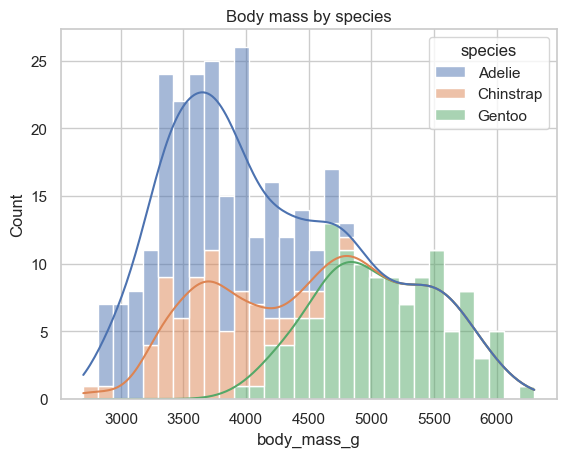

In [45]:
sns.histplot(data=df, x="body_mass_g", bins=30, kde=True, hue="species", multiple="stack")
plt.title("Body mass by species")
plt.show()

### 4b. Count plot for species and island


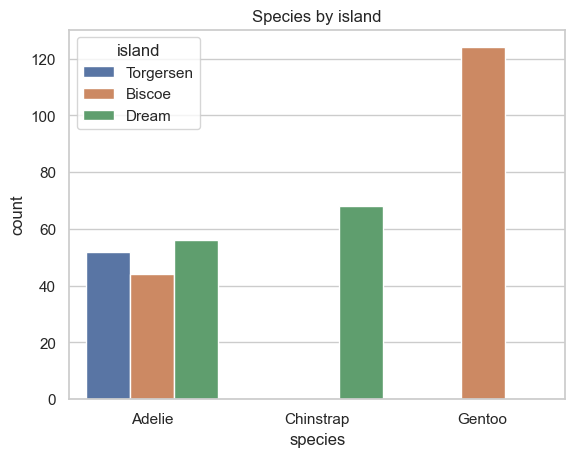

In [ ]:
sns.countplot(data=df, x="species", hue="island")
plt.title("Species by island")
plt.show()





 Reading the chart: Gentoo live only on Biscoe; Chinstrap only on Dream; Adelie live on all three islands.


### 4c. Outliers - box plot


C:\Users\AfzalTAS\AppData\Local\Temp\ipykernel_12668\686388864.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y="body_mass_g", palette="Set2")


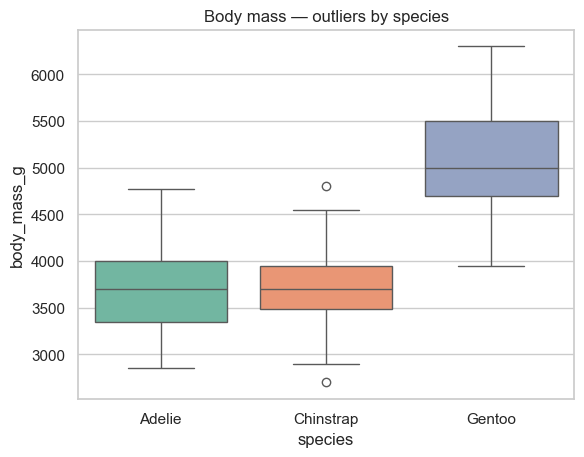

In [12]:
sns.boxplot(data=df, x="species", y="body_mass_g", palette="Set2")
plt.title("Body mass — outliers by species")
plt.show()

### 4d. Relations — correlation heatmap


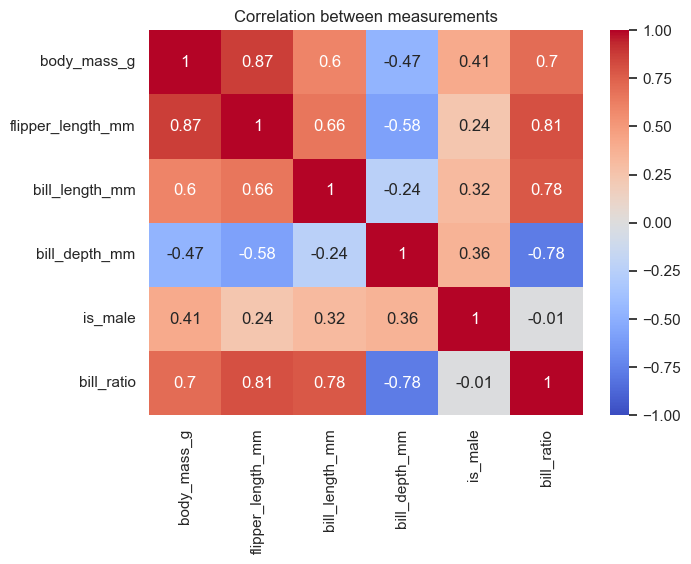

bill_depth_mm       -0.471916
is_male              0.409315
bill_length_mm       0.595110
bill_ratio           0.703119
flipper_length_mm    0.871202
body_mass_g          1.000000
Name: body_mass_g, dtype: float64


In [49]:
cols = ["body_mass_g", "flipper_length_mm", "bill_length_mm",
        "bill_depth_mm", "is_male", "bill_ratio"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between measurements")
plt.show()

print(df[cols].corr()["body_mass_g"].sort_values())

#### 5. Findings
Each finding has a number and a saved chart.

Finding#1 Species differ clearly in size


species
Adelie       3701.0
Chinstrap    3733.0
Gentoo       5076.0
Name: body_mass_g, dtype: float64


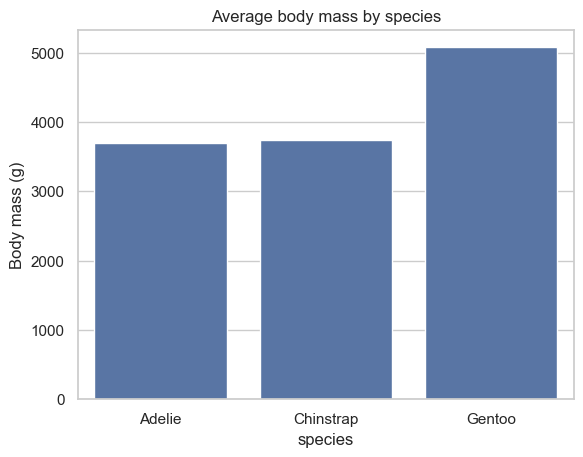

In [50]:
print(df.groupby("species")["body_mass_g"].mean().round(0))

sns.barplot(data=df, x="species", y="body_mass_g", errorbar=None)
plt.title("Average body mass by species")
plt.ylabel("Body mass (g)")
plt.savefig("mass_by_species.png", dpi=150, bbox_inches="tight")
plt.show()

#### Finding#2  Males are heavier than females (across all species)


sex
Female    3862.0
Male      4518.0
Name: body_mass_g, dtype: float64


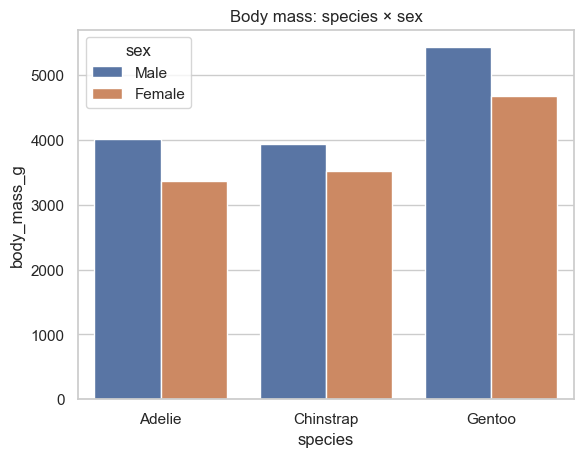

In [52]:
print(df.groupby("sex")["body_mass_g"].mean().round(0))

sns.barplot(data=df, x="species", y="body_mass_g", hue="sex", errorbar=None)
plt.title("Body mass: species × sex")
plt.savefig("mass_by_species_sex.png", dpi=150, bbox_inches="tight")
plt.show()

#### Finding#3 Flipper length is the best single predictor of weight


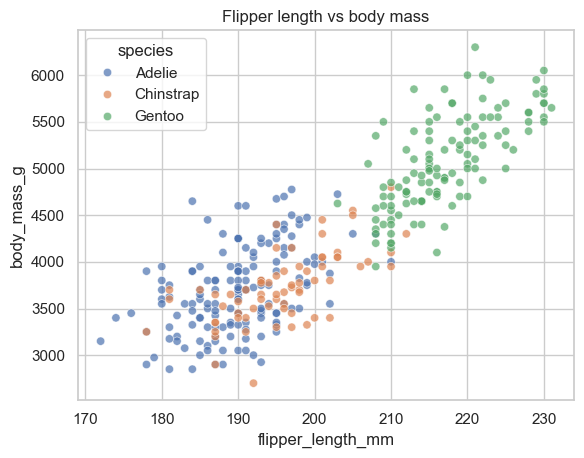

In [53]:
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g",
                hue="species", alpha=0.7)
plt.title("Flipper length vs body mass")
plt.savefig("flipper_vs_mass.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Findings

- The dataset has 344 penguins: 152 Adelie, 68 Chinstrap, and 124 Gentoo.
- 342 penguins have all four measurements. We leave missing measurements out of measurement comparisons.
- **Gentoo penguins are the heaviest on average.** Their average body mass is about **5,076 grams**, compared with about **3,701 grams** for Adelie and **3,733 grams** for Chinstrap penguins.
- **Gentoo penguins also have the longest average flippers**, about **217 mm**. The Adelie average is about **190 mm**, and the Chinstrap average is about **196 mm**
- Chinstrap have the longest bills on average (48.8 mm).
- Flipper length and body mass have a strong positive correlation (about 0.87), it is the best single number if you want to predict how heavy a penguin is. Correlation does not prove cause.
-  Gentoo live only on Biscoe, Chinstrap only on Dream.Species, So island and species carry almost the same information.